# Deep Learning Lab Assignment
## CNN Visualization & Critical Analysis
**Course:** Deep Learning & Computer Vision — Practical Laboratory

---

In [1]:
# ── CELL 1: Imports ──────────────────────────────────────────
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy.ndimage import convolve

print('All imports OK ✓')

All imports OK ✓


✓ Loaded skimage cameraman image — shape: (128, 128)


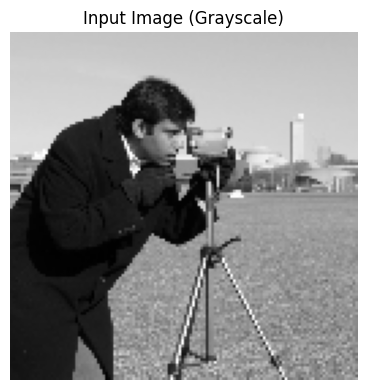

In [2]:
# ── CELL 2: Load Test Image ───────────────────────────────────
# Uses skimage built-in images — no internet needed, always works in Colab

def load_image():
    try:
        from skimage import data
        img = data.camera()          # classic 512×512 cameraman grayscale
        # Resize to 128×128 using slicing (no extra lib needed)
        step = img.shape[0] // 128
        img = img[::step, ::step][:128, :128]
        print(f'✓ Loaded skimage cameraman image — shape: {img.shape}')
        return img.astype(np.float32)
    except Exception as e:
        print(f'skimage failed ({e}) → using synthetic image')
        return make_synthetic()

def make_synthetic():
    img = np.zeros((128, 128), dtype=np.float32)
    img[20:40, :]      = 220
    img[:, 60:80]      = 180
    for i in range(40):
        img[50+i, 10+i:50+i] = float(i) * 5
    for r in range(85, 125):
        for c in range(85, 125):
            if (r//5 + c//5) % 2 == 0:
                img[r, c] = 255
    ys, xs = np.mgrid[0:128, 0:128]
    img += 120 * np.exp(-((ys-30)**2 + (xs-100)**2) / (2*12**2))
    return np.clip(img, 0, 255).astype(np.float32)

image = load_image()

plt.figure(figsize=(4, 4))
plt.imshow(image, cmap='gray')
plt.title('Input Image (Grayscale)', fontsize=12)
plt.axis('off')
plt.tight_layout()
plt.show()

In [3]:
# ── CELL 3: Define Five 3×3 Kernels ──────────────────────────

kernels = {
    'Sobel-X (Horiz Edge)': np.array([
        [-1,  0,  1],
        [-2,  0,  2],
        [-1,  0,  1]], dtype=np.float32),

    'Sobel-Y (Vert Edge)': np.array([
        [-1, -2, -1],
        [ 0,  0,  0],
        [ 1,  2,  1]], dtype=np.float32),

    'Sharpen': np.array([
        [ 0, -1,  0],
        [-1,  5, -1],
        [ 0, -1,  0]], dtype=np.float32),

    'Box Blur': np.array([
        [1/9, 1/9, 1/9],
        [1/9, 1/9, 1/9],
        [1/9, 1/9, 1/9]], dtype=np.float32),

    'Emboss': np.array([
        [-2, -1,  0],
        [-1,  1,  1],
        [ 0,  1,  2]], dtype=np.float32),
}

STAGE_LABELS = [
    'Stage A\nRaw Conv Output',
    'Stage B\nPost-ReLU',
    'Stage C\nMax Pool 2×2',
    'Stage D\nAvg Pool 2×2',
]

print('Five 3×3 kernels defined ✓')
for name, k in kernels.items():
    print(f'\n{name}:')
    print(np.round(k, 3))

Five 3×3 kernels defined ✓

Sobel-X (Horiz Edge):
[[-1.  0.  1.]
 [-2.  0.  2.]
 [-1.  0.  1.]]

Sobel-Y (Vert Edge):
[[-1. -2. -1.]
 [ 0.  0.  0.]
 [ 1.  2.  1.]]

Sharpen:
[[ 0. -1.  0.]
 [-1.  5. -1.]
 [ 0. -1.  0.]]

Box Blur:
[[0.111 0.111 0.111]
 [0.111 0.111 0.111]
 [0.111 0.111 0.111]]

Emboss:
[[-2. -1.  0.]
 [-1.  1.  1.]
 [ 0.  1.  2.]]


In [4]:
# ── CELL 4: Pipeline Functions ────────────────────────────────

def relu(x):
    """Stage B — ReLU: f(x) = max(0, x)"""
    return np.maximum(0, x)

def max_pool_2x2(fm):
    """Stage C — 2×2 Max Pooling, stride=2 (manual loop)"""
    h, w = fm.shape
    oh, ow = h // 2, w // 2
    out = np.zeros((oh, ow), dtype=np.float32)
    for i in range(oh):
        for j in range(ow):
            out[i, j] = np.max(fm[i*2:i*2+2, j*2:j*2+2])
    return out

def avg_pool_2x2(fm):
    """Stage D — 2×2 Average Pooling, stride=2 (manual loop)"""
    h, w = fm.shape
    oh, ow = h // 2, w // 2
    out = np.zeros((oh, ow), dtype=np.float32)
    for i in range(oh):
        for j in range(ow):
            out[i, j] = np.mean(fm[i*2:i*2+2, j*2:j*2+2])
    return out

def run_pipeline(img, kernel):
    """Apply all 4 stages to one filter."""
    A = convolve(img, kernel, mode='reflect')   # Stage A
    B = relu(A)                                  # Stage B
    C = max_pool_2x2(B)                          # Stage C
    D = avg_pool_2x2(B)                          # Stage D
    return A, B, C, D

print('Pipeline functions ready ✓')

Pipeline functions ready ✓


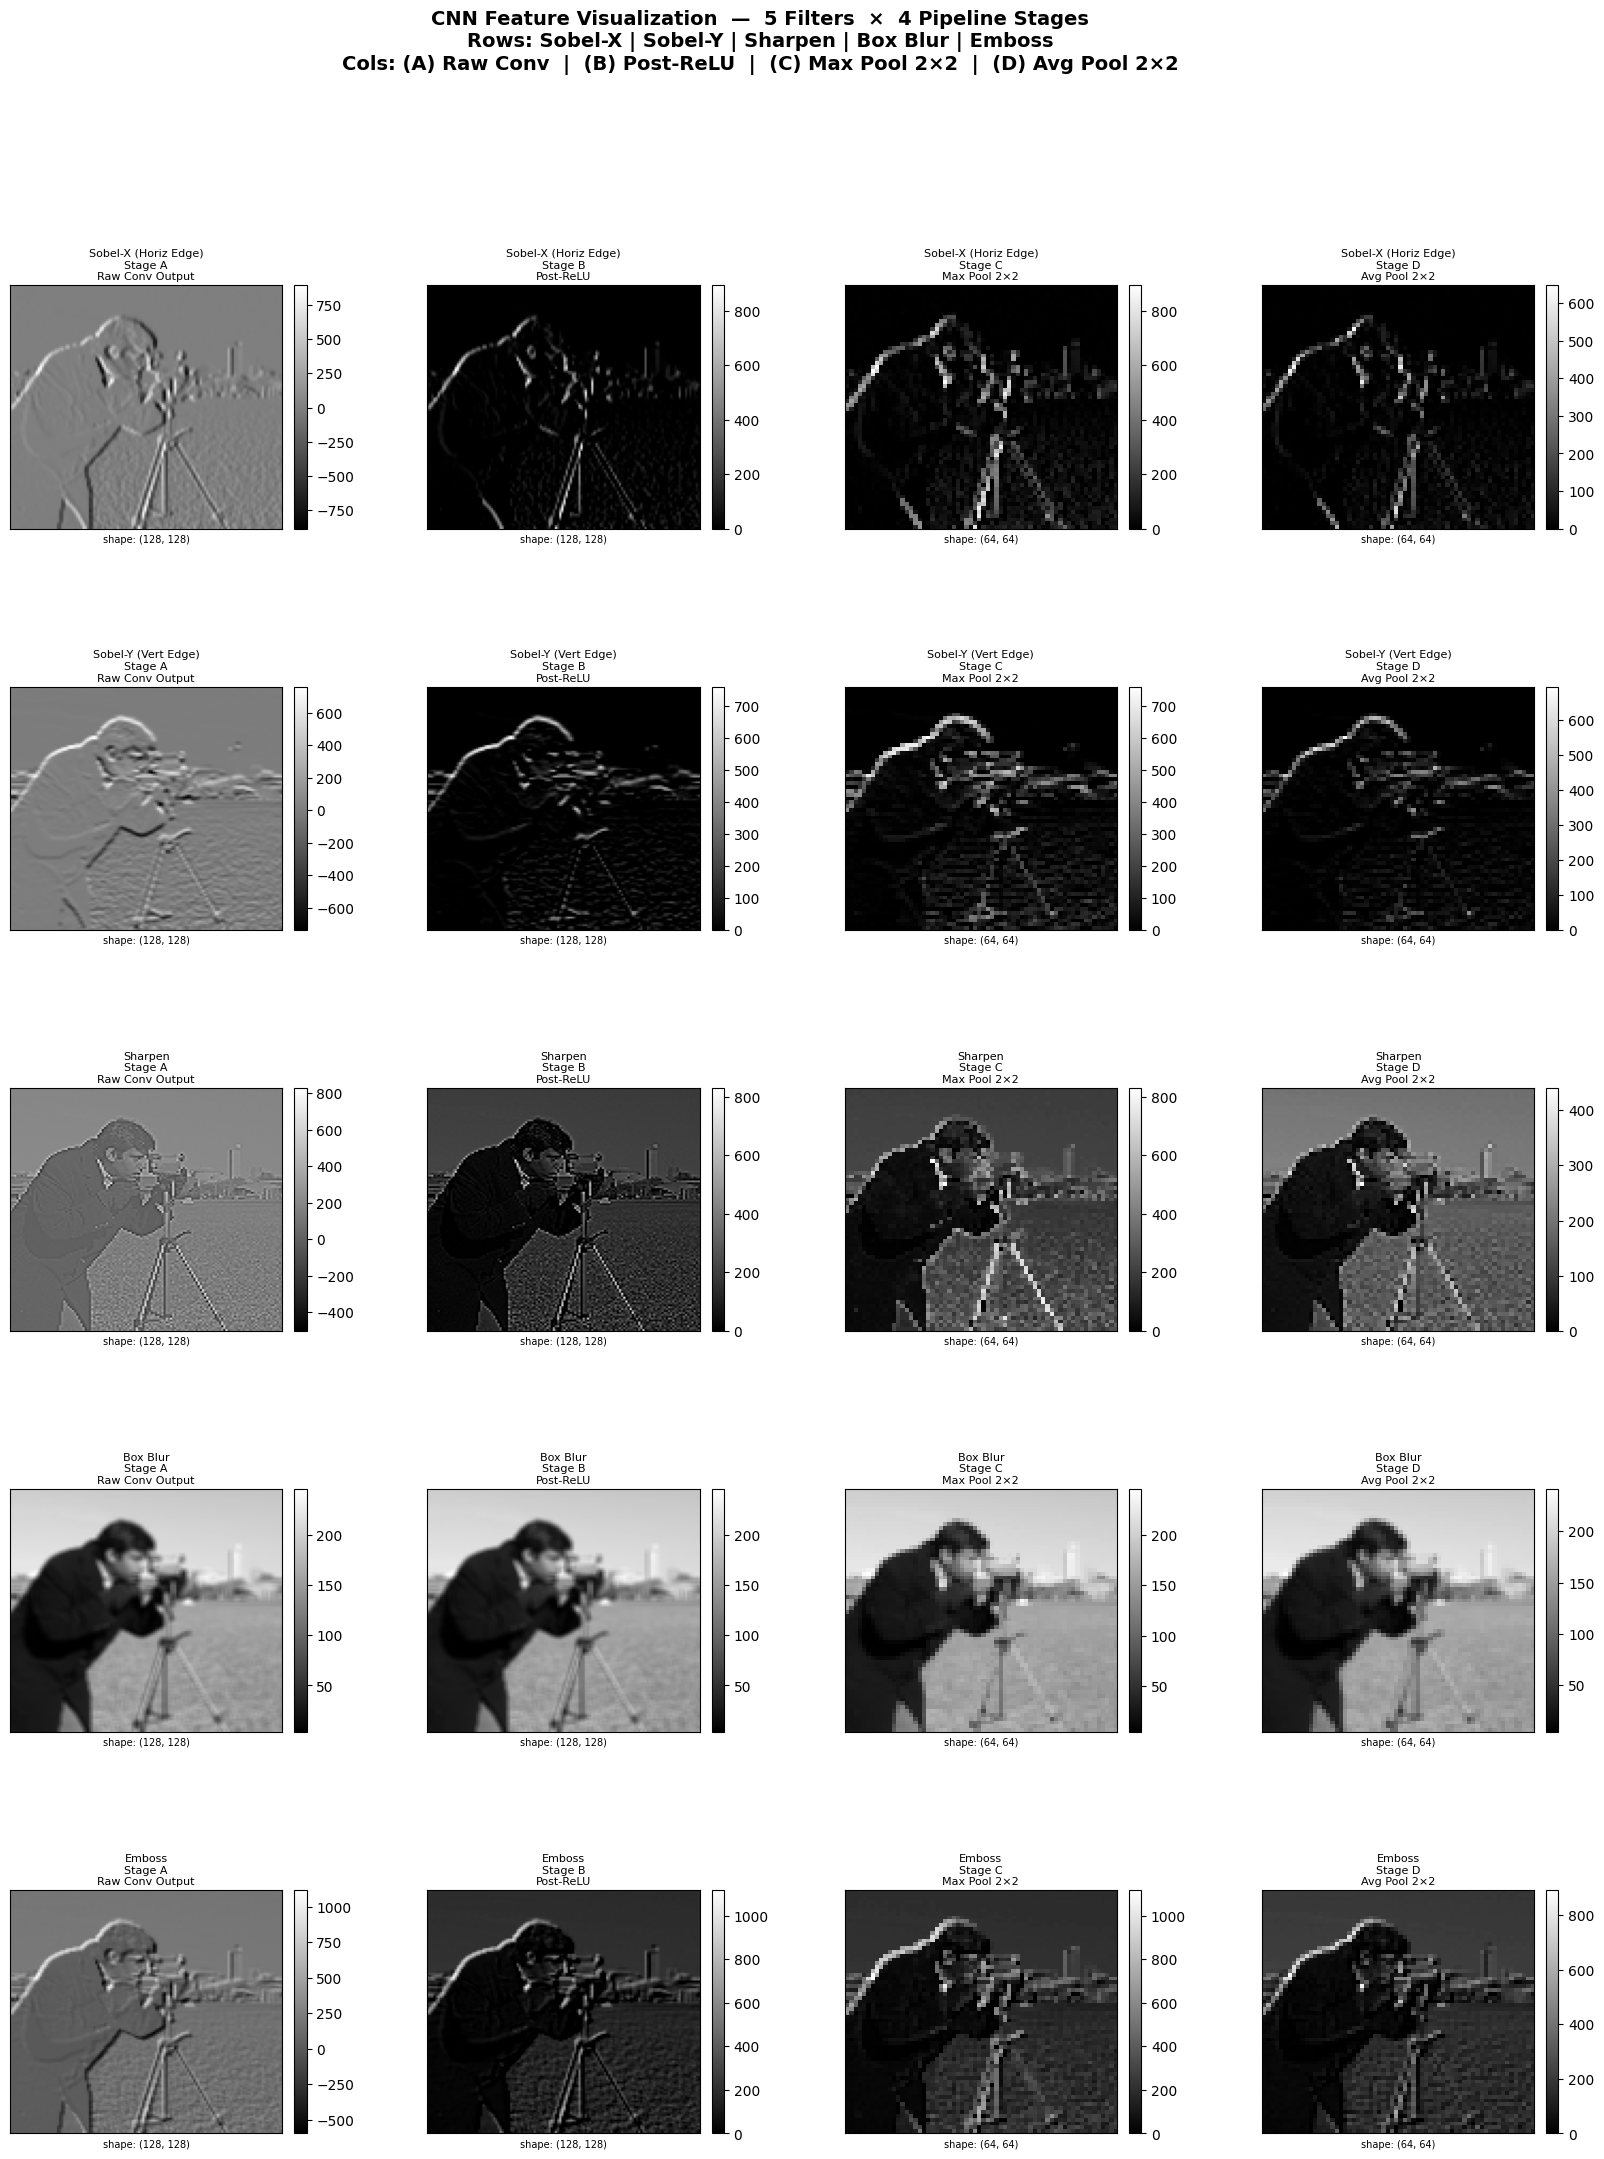

✓ Grid saved → cnn_visualization_grid.png


In [5]:
# ── CELL 5: Part I — 5×4 Visualization Grid ──────────────────

fig = plt.figure(figsize=(20, 24))
fig.suptitle(
    'CNN Feature Visualization  —  5 Filters  ×  4 Pipeline Stages\n'
    'Rows: Sobel-X | Sobel-Y | Sharpen | Box Blur | Emboss\n'
    'Cols: (A) Raw Conv  |  (B) Post-ReLU  |  (C) Max Pool 2×2  |  (D) Avg Pool 2×2',
    fontsize=14, fontweight='bold', y=0.995
)

gs = gridspec.GridSpec(5, 4, figure=fig, hspace=0.65, wspace=0.4)

for row, (fname, kernel) in enumerate(kernels.items()):
    A, B, C, D = run_pipeline(image, kernel)
    for col, (stage, label) in enumerate(zip([A, B, C, D], STAGE_LABELS)):
        ax = fig.add_subplot(gs[row, col])
        im = ax.imshow(stage, cmap='gray', aspect='auto')
        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
        ax.set_title(f'{fname}\n{label}', fontsize=8, pad=4)
        ax.set_xlabel(f'shape: {stage.shape}', fontsize=7)
        ax.set_xticks([])
        ax.set_yticks([])

plt.savefig('cnn_visualization_grid.png', dpi=130, bbox_inches='tight')
plt.show()
print('✓ Grid saved → cnn_visualization_grid.png')

In [6]:
# ── CELL 6: Part II — Manual Parameter Audit ─────────────────
# Formula:  Params = (Kh × Kw × Cin + 1) × Cout
# Assumption: padding='same' so spatial dims stay 32×32 after conv
# After each MaxPool/AvgPool (2×2 stride 2): dims halved

print('=' * 56)
print('  PART II — MANUAL PARAMETER AUDIT')
print('  Formula: (Kh × Kw × Cin + 1) × Cout')
print('=' * 56)

# ── MODEL A: 3×3, Max Pooling ─────────────────────────────────
print('\n▶  MODEL A  |  3×3 kernels  |  Max Pooling 2×2')
print('   Input: 32×32×3')

mA_c1 = (3*3*3 + 1) * 5
print(f'   Conv1  5 filters 3×3 Cin=3 : (3×3×3+1)×5  = (27+1)×5  = {mA_c1}')
print( '   → MaxPool 2×2 → 16×16×5')

mA_c2 = (3*3*5 + 1) * 10
print(f'   Conv2 10 filters 3×3 Cin=5 : (3×3×5+1)×10 = (45+1)×10 = {mA_c2}')
print( '   → MaxPool 2×2 → 8×8×10 → GlobalAvgPool → 10')

mA_d = 10*10 + 10
print(f'   Dense(10)                   : 10×10 + 10   = {mA_d}')
mA_total = mA_c1 + mA_c2 + mA_d
print(f'   {"─"*48}')
print(f'   TOTAL  =  {mA_c1} + {mA_c2} + {mA_d}  =  {mA_total} params')

# ── MODEL B: 5×5, Avg Pooling ─────────────────────────────────
print('\n▶  MODEL B  |  5×5 kernels  |  Avg Pooling 2×2')
print('   Input: 32×32×3')

mB_c1 = (5*5*3 + 1) * 5
print(f'   Conv1  5 filters 5×5 Cin=3 : (5×5×3+1)×5  = (75+1)×5  = {mB_c1}')
print( '   → AvgPool 2×2 → 16×16×5')

mB_c2 = (5*5*5 + 1) * 10
print(f'   Conv2 10 filters 5×5 Cin=5 : (5×5×5+1)×10 = (125+1)×10= {mB_c2}')
print( '   → AvgPool 2×2 → 8×8×10 → GlobalAvgPool → 10')

mB_d = 10*10 + 10
print(f'   Dense(10)                   : 10×10 + 10   = {mB_d}')
mB_total = mB_c1 + mB_c2 + mB_d
print(f'   {"─"*48}')
print(f'   TOTAL  =  {mB_c1} + {mB_c2} + {mB_d}  =  {mB_total} params')

# ── Comparison ─────────────────────────────────────────────────
pct = (mB_total - mA_total) / mA_total * 100
print(f'\n▶  % INCREASE')
print(f'   = ({mB_total} − {mA_total}) / {mA_total} × 100')
print(f'   = {mB_total - mA_total} / {mA_total} × 100')
print(f'   = {pct:.2f}%')

  PART II — MANUAL PARAMETER AUDIT
  Formula: (Kh × Kw × Cin + 1) × Cout

▶  MODEL A  |  3×3 kernels  |  Max Pooling 2×2
   Input: 32×32×3
   Conv1  5 filters 3×3 Cin=3 : (3×3×3+1)×5  = (27+1)×5  = 140
   → MaxPool 2×2 → 16×16×5
   Conv2 10 filters 3×3 Cin=5 : (3×3×5+1)×10 = (45+1)×10 = 460
   → MaxPool 2×2 → 8×8×10 → GlobalAvgPool → 10
   Dense(10)                   : 10×10 + 10   = 110
   ────────────────────────────────────────────────
   TOTAL  =  140 + 460 + 110  =  710 params

▶  MODEL B  |  5×5 kernels  |  Avg Pooling 2×2
   Input: 32×32×3
   Conv1  5 filters 5×5 Cin=3 : (5×5×3+1)×5  = (75+1)×5  = 380
   → AvgPool 2×2 → 16×16×5
   Conv2 10 filters 5×5 Cin=5 : (5×5×5+1)×10 = (125+1)×10= 1260
   → AvgPool 2×2 → 8×8×10 → GlobalAvgPool → 10
   Dense(10)                   : 10×10 + 10   = 110
   ────────────────────────────────────────────────
   TOTAL  =  380 + 1260 + 110  =  1750 params

▶  % INCREASE
   = (1750 − 710) / 710 × 100
   = 1040 / 710 × 100
   = 146.48%


In [7]:
# ── CELL 7: Keras model.summary() — Framework Verification ───
import tensorflow as tf
from tensorflow.keras import layers, models

print(f'TensorFlow version: {tf.__version__}')

def build_model_A():
    return models.Sequential([
        layers.Input(shape=(32, 32, 3)),
        layers.Conv2D(5,  (3,3), activation='relu', padding='same', name='Conv1_3x3'),
        layers.MaxPooling2D((2,2), name='MaxPool1'),
        layers.Conv2D(10, (3,3), activation='relu', padding='same', name='Conv2_3x3'),
        layers.MaxPooling2D((2,2), name='MaxPool2'),
        layers.GlobalAveragePooling2D(name='GAP'),
        layers.Dense(10, activation='softmax', name='Output'),
    ], name='Model_A_3x3_MaxPool')

def build_model_B():
    return models.Sequential([
        layers.Input(shape=(32, 32, 3)),
        layers.Conv2D(5,  (5,5), activation='relu', padding='same', name='Conv1_5x5'),
        layers.AveragePooling2D((2,2), name='AvgPool1'),
        layers.Conv2D(10, (5,5), activation='relu', padding='same', name='Conv2_5x5'),
        layers.AveragePooling2D((2,2), name='AvgPool2'),
        layers.GlobalAveragePooling2D(name='GAP'),
        layers.Dense(10, activation='softmax', name='Output'),
    ], name='Model_B_5x5_AvgPool')

print('\n' + '='*56)
print('  MODEL A — model.summary()')
print('='*56)
mA = build_model_A()
mA.summary()

print('\n' + '='*56)
print('  MODEL B — model.summary()')
print('='*56)
mB = build_model_B()
mB.summary()

print('\n' + '─'*56)
keras_A = mA.count_params()
keras_B = mB.count_params()
mA_ok = '✓ MATCH' if mA_total == keras_A else f'✗ MISMATCH (Keras={keras_A})'
mB_ok = '✓ MATCH' if mB_total == keras_B else f'✗ MISMATCH (Keras={keras_B})'
print(f'  Model A  Manual={mA_total}  Keras={keras_A}  → {mA_ok}')
print(f'  Model B  Manual={mB_total}  Keras={keras_B}  → {mB_ok}')
print('─'*56)

TensorFlow version: 2.21.0

  MODEL A — model.summary()


Model: "Model_A_3x3_MaxPool"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Conv1_3x3 (Conv2D)              │ (None, 32, 32, 5)      │           140 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MaxPool1 (MaxPooling2D)         │ (None, 16, 16, 5)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv2_3x3 (Conv2D)              │ (None, 16, 16, 10)     │           460 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MaxPool2 (MaxPooling2D)         │ (None, 8, 8, 10)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ GAP (GlobalAveragePooling2D)    │ (None, 10)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output (Dense)                  │ (None, 10)             │           110 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 710 (2.77 KB)

 Trainable params: 710 (2.77 KB)

 Non-trainable params: 0 (0.00 B)

... (3 outputs left out)

 Total params: 1,750 (6.84 KB)

 Trainable params: 1,750 (6.84 KB)

 Non-trainable params: 0 (0.00 B)


────────────────────────────────────────────────────────
  Model A  Manual=710  Keras=710  → ✓ MATCH
  Model B  Manual=1750  Keras=1750  → ✓ MATCH
────────────────────────────────────────────────────────


In [8]:
# ── CELL 8: Q4 — Numerical Commutativity Proof ───────────────
# Proves Conv→ReLU→MaxPool ≡ Conv→MaxPool→ReLU

print('=' * 56)
print('  Q4 — ORDER COMMUTATIVITY PROOF')
print('  Conv→ReLU→MaxPool  vs  Conv→MaxPool→ReLU')
print('=' * 56)

test_cases = [
    ('Mixed pos dominant',  np.array([[-3.,  2.], [ 5., -1.]])),
    ('All negative',        np.array([[-3., -2.], [-5., -1.]])),
    ('All positive',        np.array([[ 3.,  2.], [ 5.,  1.]])),
    ('Zero present',        np.array([[ 0.,  2.], [-3., -1.]])),
    ('Single survivor',     np.array([[-9., -8.], [ 0.1,-7.]])),
]

print(f'\n  {"Patch":<22} {"Max":>6}  {"C→R→P":>8}  {"C→P→R":>8}  {"Result":>10}')
print('  ' + '─'*58)
for label, patch in test_cases:
    crp = float(np.max(np.maximum(0., patch)))     # Conv → ReLU → MaxPool
    cpr = float(max(0., float(np.max(patch))))     # Conv → MaxPool → ReLU
    ok  = '✓ EQUAL' if np.isclose(crp, cpr) else '✗ DIFFER'
    print(f'  {label:<22} {np.max(patch):>6.2f}  {crp:>8.2f}  {cpr:>8.2f}  {ok:>10}')

print('''
  ── Mathematical Proof ──
  Claim:  MaxPool(ReLU(X)) = ReLU(MaxPool(X))  for all X

  Lemma:  For any monotone non-decreasing f:
          max(f(x1), f(x2), …, f(xn)) = f(max(x1, …, xn))

  ReLU(x) = max(0, x) is monotone non-decreasing.
  Therefore the lemma applies → the two orders are identical.

  Efficiency gain:
  Conv→MaxPool→ReLU applies ReLU to N/4 values (after 2×2
  stride-2 pool) rather than N — saving 75% of ReLU ops.
''')

print('All cells complete ✓')

  Q4 — ORDER COMMUTATIVITY PROOF
  Conv→ReLU→MaxPool  vs  Conv→MaxPool→ReLU

  Patch                     Max     C→R→P     C→P→R      Result
  ──────────────────────────────────────────────────────────
  Mixed pos dominant       5.00      5.00      5.00     ✓ EQUAL
  All negative            -1.00      0.00      0.00     ✓ EQUAL
  All positive             5.00      5.00      5.00     ✓ EQUAL
  Zero present             2.00      2.00      2.00     ✓ EQUAL
  Single survivor          0.10      0.10      0.10     ✓ EQUAL

  ── Mathematical Proof ──
  Claim:  MaxPool(ReLU(X)) = ReLU(MaxPool(X))  for all X

  Lemma:  For any monotone non-decreasing f:
          max(f(x1), f(x2), …, f(xn)) = f(max(x1, …, xn))

  ReLU(x) = max(0, x) is monotone non-decreasing.
  Therefore the lemma applies → the two orders are identical.

  Efficiency gain:
  Conv→MaxPool→ReLU applies ReLU to N/4 values (after 2×2
  stride-2 pool) rather than N — saving 75% of ReLU ops.

All cells complete ✓
